(See units 17-18)

**Problem 7.1 Principal Axes of a Distribution** 

Suppose we represent an extended 2D system as a set of $N$ equal mass elements or particles, with positions $(x_i,y_i)$. 
 
The *moment of inertia tensor* is a matrix $I$ such that the angular momentum vector of the system is

$$\vec{L} = I\vec{\omega}\,,$$

where $\vec{\omega}$ is the angular velocity vector.

The coefficients of $I$ are:

$$I_{00} = \sum (y_i-\bar{y})^2$$
$$I_{01} = \sum (x_i-\bar{x})*(y_i-\bar{y})$$
$$I_{10} = \sum (y_i-\bar{y})*(x_i-\bar{x})$$
$$I_{11} = \sum (x_i-\bar{x})^2$$

where $\bar{x} = (1/N)\sum x_i$ and $\bar{y} = (1/N)\sum y_i$ are the average values of these coordinates.

Then the eigenvectors of the moment of inertia tensor are the *principal axes*, or symmetry axes, of the system.

**a)** Using the code below, you can generate a rotated, ellipsoidal distribution of points in 2D. Calculate the mean values of the $x_i$ and $y_i$, and then the moment of inertia tensor. 

**b)** Determine the eigenvectors of the moment of inertia tensor (print them out), and plot these as arrows starting from $\bar{x}, \bar{y}$, along with the rotated points, to show they are indeed the axes of symmetry. *Hint: note that moment of inertia tensors are real and symmetric, and thus hermitian; this may affect the Python function(s) you choose to use.*

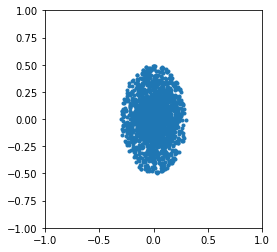

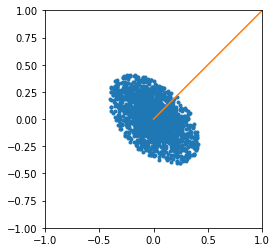

In [3]:
from numpy import array, zeros, mean, sqrt, outer
from numpy.linalg import eigh
from matplotlib.pyplot import plot, show, arrow, gca, xlim, ylim
from random import random
from math import cos, sin, pi, tanh, atan, tan

# 1) make arrays to hold N x,y values
N = 3000
x = zeros(N, float)
y = zeros(N, float)

# set principal axis lengths
A = 0.3
B = 0.5
C = 0.2

# 2) make ellipsoidal distribution
r = 0.0
th = 0.0
for i in range(N):
    r = random()        #random radius
    r = r*r     # this concentrates the points a bit more
    th = random()*2.0*pi # random angle
    x[i] = A*r*cos(th)
    y[i] = B*r*sin(th)

# turn this on if you want to plot the initial distribution
if(1):
    plot(x,y, marker='.', ls='')
    ax = gca()
    xlim(-1,1)
    ylim(-1,1)
    ax.set_aspect('equal')
    show()

# 3) now rotate the distribution
theta = 30.0
theta_r = pi*(45.0/180.0) # in radians
ct = cos(theta_r)
st = sin(theta_r)
x2 = zeros(len(x))
y2 = zeros(len(y))
for i in range(N):
    x2[i] = ct*x[i] - st*y[i]
    y2[i] = st*x[i] + ct*y[i]

# turn this on if you want to plot the rotated distribution
if(1):
    xlim(-1,1)
    ylim(-1,1)
    ax = gca()
    ax.set_aspect('equal')
    plot(x2,y2, marker='.', ls='')
    plot([0,1],[0,1])
    show()


(a) 

In [8]:
import numpy as np

# calculate mean of x, y
mu_x = np.mean(x2)
mu_y = np.mean(y2)

print("Mean of x: " + str(mu_x))
print("Mean of y: " + str(mu_y))

# tensor matrix
mat = np.zeros((2, 2))
mat[0, 0] = np.linalg.norm(y2 - mu_y) ** 2
mat[1, 0] = mat[0, 1] = np.dot(x2 - mu_x, y2 - mu_y)
mat[1, 1] = np.linalg.norm(y2 - mu_x) ** 2

print("Moment of inertia tensor: ")
print(mat)

Mean of x: -0.0026175034486885856
Mean of y: 0.0027263842691628427
Moment of inertia tensor: 
[[ 52.98580615 -25.10018237]
 [-25.10018237  53.07147755]]


(b)

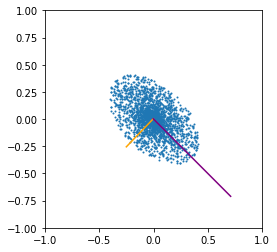

In [32]:
import matplotlib.pyplot as plt

eigenvalues, eigenvecs = np.linalg.eig(mat)
    
plt.figure(1)
plt.xlim(-1, 1)
plt.ylim(-1, 1)
ax = plt.gca()
ax.set_aspect('equal')
plt.scatter(x2, y2, 1)

eigenvecs[:, 0] *= eigenvalues[0] / max(eigenvalues)
eigenvecs[:, 1] *= eigenvalues[1] / max(eigenvalues)

xs = [mu_x, eigenvecs[0, 0] - mu_x, eigenvecs[0, 1] - mu_x]
ys = [mu_y, eigenvecs[1, 0] - mu_y, eigenvecs[1, 1] - mu_y]

plt.plot(xs[:2], ys[:2], c='orange')
plt.plot([xs[0], xs[2]], [ys[0], ys[2]], c='purple')

**Problem 7.2 The Earth-Sun Lagrange Point L1**

Consider the Lagrange points of the Earth-Sun system. The point $L1$ along the Sun-Earth line is the place where the forces from the two bodies cancel out, in a corotating frame with an extra centrifugal force term.

Given the expression for the net force fG in the corotating frame given in the code stub below, solve for the root $x^*$ such that $fG(x^*) = 0$, using Newton's method or the secant method to find the root. (Note we want the root *between* the Sun and the Earth; there are other roots outside this interval.) You may wish to plot the function $fG$ first, to estimate roughly where the root is.

In [33]:
# find the Sun-Earth Lagrange point L1, using Newton's method

from numpy import arange, zeros, ones
from pylab import plot, show, xlim, ylim, xlabel, ylabel

# physical parameters
G = 6.674e-11 # Newton's gravitational constant in SI units (m^3 kg^-1 s^-2_
Me = 5.974e24 # Mass of the Earth in SI units (kg) 
Ms = 1.989e30 # Mass of the Sun in SI units (kg)

R = 1.496e11  # 1AU = mean Earth-Sun distance (m)
w = 1.99e-7 # Earth's orbital frequency (rad s^-1)

#the function whose root we want to find (force along the Sun-Earth line)
def fG(x):
    return G * Ms / x / x - G * Me / (R - x) / (R - x) - w * w * x


Text(0, 0.5, 'log(y)')

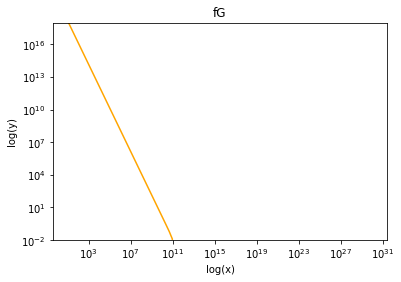

In [86]:
# plot fG
xs = 10 ** np.linspace(1, 30, 100)
ys = fG(xs)

plt.figure(2)
plt.loglog(xs, ys, c='orange')
plt.ylim(0.01, 10**18)
plt.title("fG")
plt.xlabel("log(x)")
plt.ylabel("log(y)")

We can know from the graph that the approximate solution is above $10^{10}$

In [79]:
def fGp(x): # derivatives
    return G * Ms * (-2) / (x ** 3) - G * Me * 2 / (R - x) ** 3 - w * w

def newton(f, fp, x0, err=1, max_iter=1000):
    x0 = x0
    x1 = 1 << 32
    ind = 0
    while np.linalg.norm(x0 - x1) > err and ind < max_iter:
        x0 = x1
        x1 = x1 - f(x1) / fp(x1)
        ind += 1
    return x1

In [82]:
res = newton(fG, fGp, 1e10, 1e-7)

print("Root: ")
print(res)

print("fG(x): ")
print(fG(res))

Root: 
148127607098.60184
fG(x): 
2.6020852139652106e-18


In [84]:
res < R

True